In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from glob import glob

/gpfs/home/qcf21tku/.conda/envs/bio/lib/python3.9/site-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


In [71]:
coord_path = "/gpfs/data/mock_lab/will/mosaic_tmp/mag_catalogue/vir/binning/vamb_out_v1/umap_out.tsv"
mbat_bins_path = "/gpfs/data/mock_lab/will/mosaic_tmp/mag_catalogue/vir/binning/metabat_out_v1.tsv"
vamb_bins_path = "/gpfs/data/mock_lab/will/mosaic_tmp/mag_catalogue/vir/binning/vamb_out_v1/vae_clusters.tsv"
lengths_npz = "/gpfs/data/mock_lab/will/mosaic_tmp/mag_catalogue/vir/binning/vamb_out_v1/lengths.npz"

df_umap_coords = pd.read_csv(coord_path, sep = '\t')
df_umap_coords['sample'] = df_umap_coords.contig_id.apply(lambda x: x.split('_')[0])
df_umap_coords.head()

,contig_id,umap_0,umap_1,sample
0,3300069126_Ga0613337_0000588,-4.149927,14.475649,3300069126
1,3300069126_Ga0613337_0000621,-6.045347,7.693256,3300069126
2,3300069126_Ga0613337_0001030,-6.049957,7.683440,3300069126
3,3300069126_Ga0613337_0001122,-12.859436,-6.992188,3300069126
4,3300069126_Ga0613337_0001165,-6.036482,7.687197,3300069126


In [16]:
mbat_bins = pd.read_csv(
    mbat_bins_path, 
    sep = '\t', 
    names = ['mbat_bin_id', 'contig_id']
)

vamb_bins = pd.read_csv(
    vamb_bins_path, 
    sep = '\t', 
    names = ['vamb_bin_id', 'contig_id']
)


In [13]:
df_tax = pd.concat(
    (pd.read_csv(f, sep = '\t').rename(columns = {"seq_name":"contig_id"})[["contig_id", "taxonomy"]]
         for f in 
     glob("/gpfs/data/mock_lab/will/mosaic_tmp/genomad/*/*.euks_summary/*.euks_virus_summary.tsv")
), axis = 0)

/tmp/ipykernel_13044/1350308647.py:2: DtypeWarning: Columns (3) have mixed types. Specify dtype option on import or set low_memory=False.
  (pd.read_csv(f, sep = '\t').rename(columns = {"seq_name":"contig_id"})[["contig_id", "taxonomy"]]


In [196]:
df = pd.merge(df_umap_coords, mbat_bins, how = 'left', on = 'contig_id').fillna("none")
df = pd.merge(df, vamb_bins, how = 'left', on = 'contig_id').fillna("none")
df = pd.merge(df, df_tax, how = 'left', on = 'contig_id').fillna("none")
df.head()

,contig_id,umap_0,umap_1,sample,mbat_bin_id,vamb_bin_id,taxonomy
0,3300069126_Ga0613337_0000588,-4.149927,14.475649,3300069126,metabat_out_v1.43663,vae_370,Viruses;Varidnaviria;Bamfordvirae;Nucleocytovi...
1,3300069126_Ga0613337_0000621,-6.045347,7.693256,3300069126,metabat_out_v1.42687,vae_5022,Viruses;Varidnaviria;Bamfordvirae;Nucleocytovi...
2,3300069126_Ga0613337_0001030,-6.049957,7.683440,3300069126,metabat_out_v1.42687,vae_5022,Viruses;Varidnaviria;Bamfordvirae;Nucleocytovi...
3,3300069126_Ga0613337_0001122,-12.859436,-6.992188,3300069126,metabat_out_v1.69194,vae_2225,Viruses;Varidnaviria;Bamfordvirae;Nucleocytovi...
4,3300069126_Ga0613337_0001165,-6.036482,7.687197,3300069126,metabat_out_v1.42687,vae_5022,Viruses;;;;;;


In [152]:
for f in set(df.taxonomy):
    print(f)

Viruses;Riboviria;Orthornavirae;Pisuviricota;Pisoniviricetes;Picornavirales;
Viruses;Varidnaviria;Bamfordvirae;Preplasmiviricota;Tectiliviricetes;;Autolykiviridae
Viruses;Riboviria;Pararnavirae;Artverviricota;Revtraviricetes;Ortervirales;Retroviridae
Viruses;Duplodnaviria;Heunggongvirae;Uroviricota;Caudoviricetes;;Drexlerviridae
Viruses;Duplodnaviria;Heunggongvirae;Uroviricota;Caudoviricetes;;Mesyanzhinovviridae
Viruses;Adnaviria;Zilligvirae;Taleaviricota;Tokiviricetes;Ligamenvirales;Lipothrixviridae
Viruses;Monodnaviria;Shotokuvirae;Cressdnaviricota;Arfiviricetes;Cirlivirales;Circoviridae
Viruses;Riboviria;Orthornavirae;Kitrinoviricota;Alsuviricetes;Martellivirales;
Viruses;Duplodnaviria;Heunggongvirae;Uroviricota;Caudoviricetes;;
Viruses;Duplodnaviria;Heunggongvirae;Uroviricota;Caudoviricetes;;Herelleviridae
Viruses;Riboviria;Orthornavirae;Duplornaviricota;Chrymotiviricetes;Ghabrivirales;
Viruses;;;;Naldaviricetes;Lefavirales;Hytrosaviridae
Viruses;Varidnaviria;Bamfordvirae;Preplasmi

In [197]:
known_phyla = [
    "Caudoviricetes", 
    "Phycodnaviridae", 
    "Mimiviridae", 
    "Megaviricetes", 
    "Nucleocytoviricota", 
    "Sangervirae",
    "Preplasmiviricota", 
    "Shotokuvirae", 
    "Riboviria"
]

def make_simple_taxonomy(tax_col):
    if tax_col in ["Unclassified", "none", "Viruses;;;;;;", "Viruses;Varidnaviria;Bamfordvirae;;;;"]:
        return "unknown"
    for phy in known_phyla:
        if phy in tax_col:
            return phy
    
    return "other"

def fix_taxonomy_2(row):
    
    if row.bin_all != "unbinned":
        bin_str = f"vir_{row.bin_all}"
    
    else:
        bin_str = "vir_unbinned"
    
    if row.taxonomy in ["Unclassified", "none", "Viruses;;;;;;", "Viruses;Varidnaviria;Bamfordvirae;;;;"]:
        return f"{bin_str}_unknown"
    
    most_specific_name = [x for x in row.taxonomy.split(";") if len(x) > 0][-1]
    
    if not row.name_simple in ["other", "unknown"]:
        
        if row.name_simple.lower() == most_specific_name.lower():
            return f"{bin_str}_{most_specific_name.lower()}"
        
        return f"{bin_str}_{row.name_simple.lower()}_{most_specific_name.lower()}"
    
    return f"{bin_str}_unknown"


df['name_simple'] = df.taxonomy.apply(make_simple_taxonomy)


lengths = np.load(lengths_npz)['arr_0']
df['lengths'] = lengths

In [198]:
df_mt = df.groupby('mbat_bin_id')[['lengths']].sum().reset_index().sort_values("lengths", ascending = False)
df_vt = df.groupby('vamb_bin_id')[['lengths']].sum().reset_index().sort_values("lengths", ascending = False)


df2 = df[df.mbat_bin_id.isin(
    set(df_mt.tail(-1).head(2500).mbat_bin_id)
) | df.vamb_bin_id.isin(
    set(df_vt.head(2500).vamb_bin_id)
)]

s = set(df_vt.head(2500).vamb_bin_id)
s2 = set(df_mt.tail(-1).head(2500).mbat_bin_id)

def choose_row(r):
    
    if r.vamb_bin_id in s:
        return r.vamb_bin_id
    elif r.mbat_bin_id in s2:
        return r.mbat_bin_id
    
    return "unbinned"

df2['bin_all'] = df2.apply(choose_row, axis = 1)

/tmp/ipykernel_13044/1159667796.py:23: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df2['bin_all'] = df2.apply(choose_row, axis = 1)


In [199]:
df['bin_all'] = df.apply(choose_row, axis = 1)
df['bin_name'] = df.apply(fix_taxonomy_2, axis = 1)

In [200]:
df.head()

,contig_id,umap_0,umap_1,sample,mbat_bin_id,vamb_bin_id,taxonomy,name_simple,lengths,bin_all,bin_name
0,3300069126_Ga0613337_0000588,-4.149927,14.475649,3300069126,metabat_out_v1.43663,vae_370,Viruses;Varidnaviria;Bamfordvirae;Nucleocytovi...,Phycodnaviridae,50864,vae_370,vir_vae_370_phycodnaviridae
1,3300069126_Ga0613337_0000621,-6.045347,7.693256,3300069126,metabat_out_v1.42687,vae_5022,Viruses;Varidnaviria;Bamfordvirae;Nucleocytovi...,Megaviricetes,49599,vae_5022,vir_vae_5022_megaviricetes
2,3300069126_Ga0613337_0001030,-6.049957,7.683440,3300069126,metabat_out_v1.42687,vae_5022,Viruses;Varidnaviria;Bamfordvirae;Nucleocytovi...,Megaviricetes,39566,vae_5022,vir_vae_5022_megaviricetes
3,3300069126_Ga0613337_0001122,-12.859436,-6.992188,3300069126,metabat_out_v1.69194,vae_2225,Viruses;Varidnaviria;Bamfordvirae;Nucleocytovi...,Megaviricetes,38156,vae_2225,vir_vae_2225_megaviricetes
4,3300069126_Ga0613337_0001165,-6.036482,7.687197,3300069126,metabat_out_v1.42687,vae_5022,Viruses;;;;;;,unknown,37512,vae_5022,vir_vae_5022_unknown


In [201]:
df_dedup = df[
    ['bin_all', 'bin_name']
].value_counts(
    subset=['bin_all', 'bin_name']
).to_frame().reset_index().rename(columns = {0:"count"})

df_dedup = df_dedup[df_dedup.bin_all != "unbinned"]

df_dedup = df_dedup.sort_values(
    "count", ascending = False
)

print(len(set(df_dedup.bin_all)))

df_dedup = df_dedup.loc[
    df_dedup.groupby('bin_all')['count'].idxmax()
][['bin_all', 'bin_name', 'count']].reset_index(
    drop=True
)

df_dedup.head(30)

4538


,bin_all,bin_name,count
0,metabat_out_v1.10292,vir_metabat_out_v1.10292_megaviricetes,1
1,metabat_out_v1.10458,vir_metabat_out_v1.10458_unknown,1
2,metabat_out_v1.10459,vir_metabat_out_v1.10459_unknown,2
3,metabat_out_v1.10461,vir_metabat_out_v1.10461_phycodnaviridae,1
4,metabat_out_v1.10465,vir_metabat_out_v1.10465_phycodnaviridae,1
5,metabat_out_v1.10505,vir_metabat_out_v1.10505_unknown,31
6,metabat_out_v1.10594,vir_metabat_out_v1.10594_unknown,4
7,metabat_out_v1.10616,vir_metabat_out_v1.10616_caudoviricetes,8
8,metabat_out_v1.10634,vir_metabat_out_v1.10634_phycodnaviridae,7
9,metabat_out_v1.10643,vir_metabat_out_v1.10643_mimiviridae,3


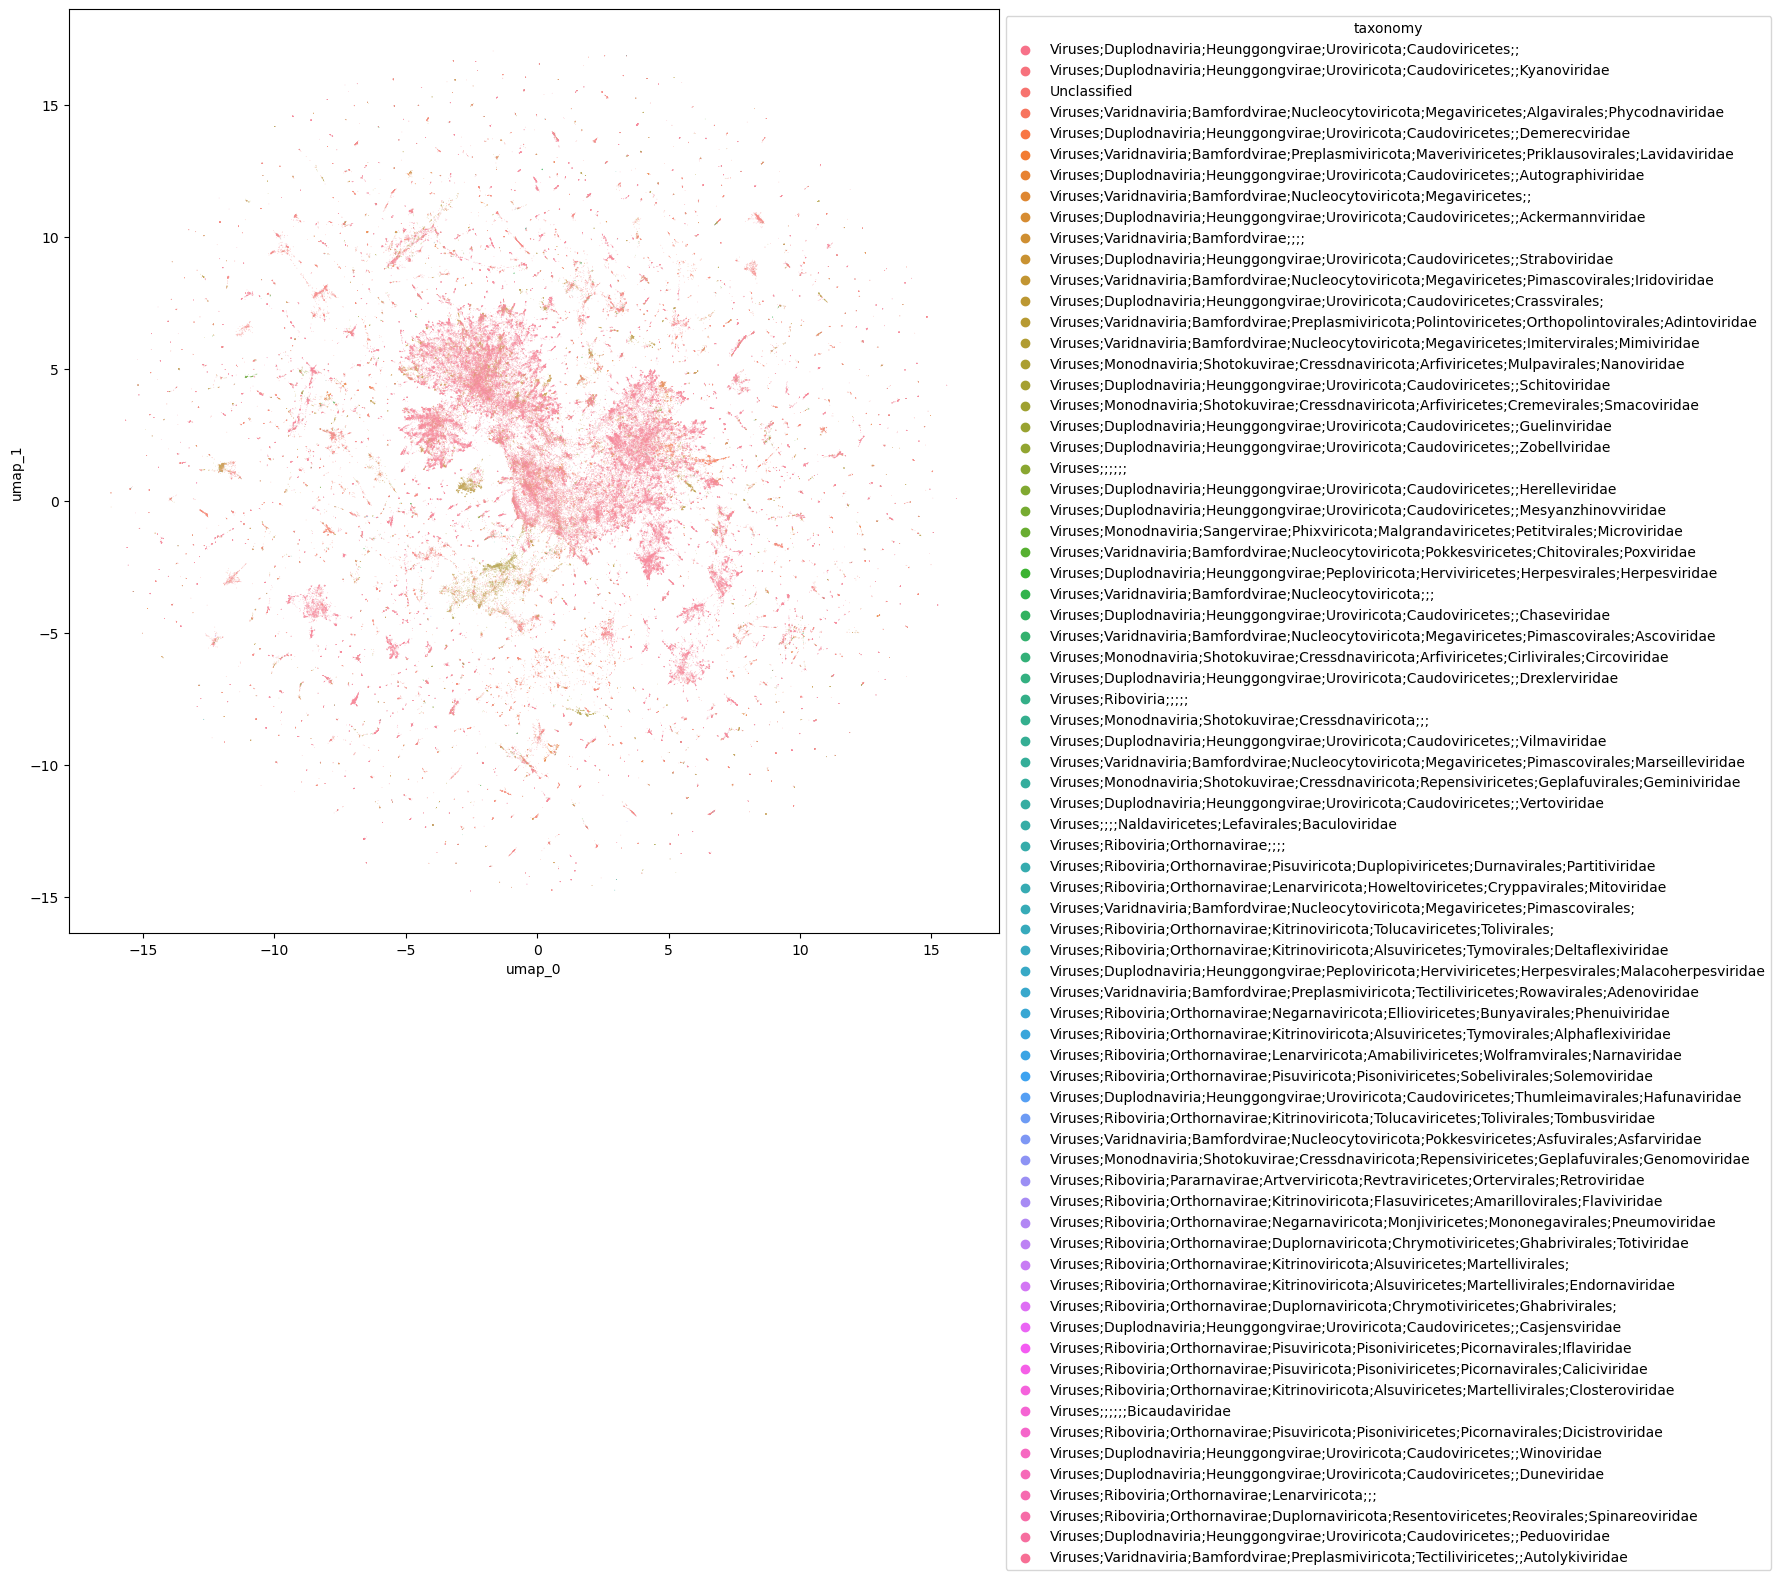

In [153]:
plt.figure(figsize = (12, 12))
ax = sns.scatterplot(
    data = df[df.mbat_bin_id == "metabat_out_v1.unbinned"], 
    x = 'umap_0', 
    y = 'umap_1', 
    s = 0.25, 
    alpha = 0.5, 
    hue = 'taxonomy'
)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

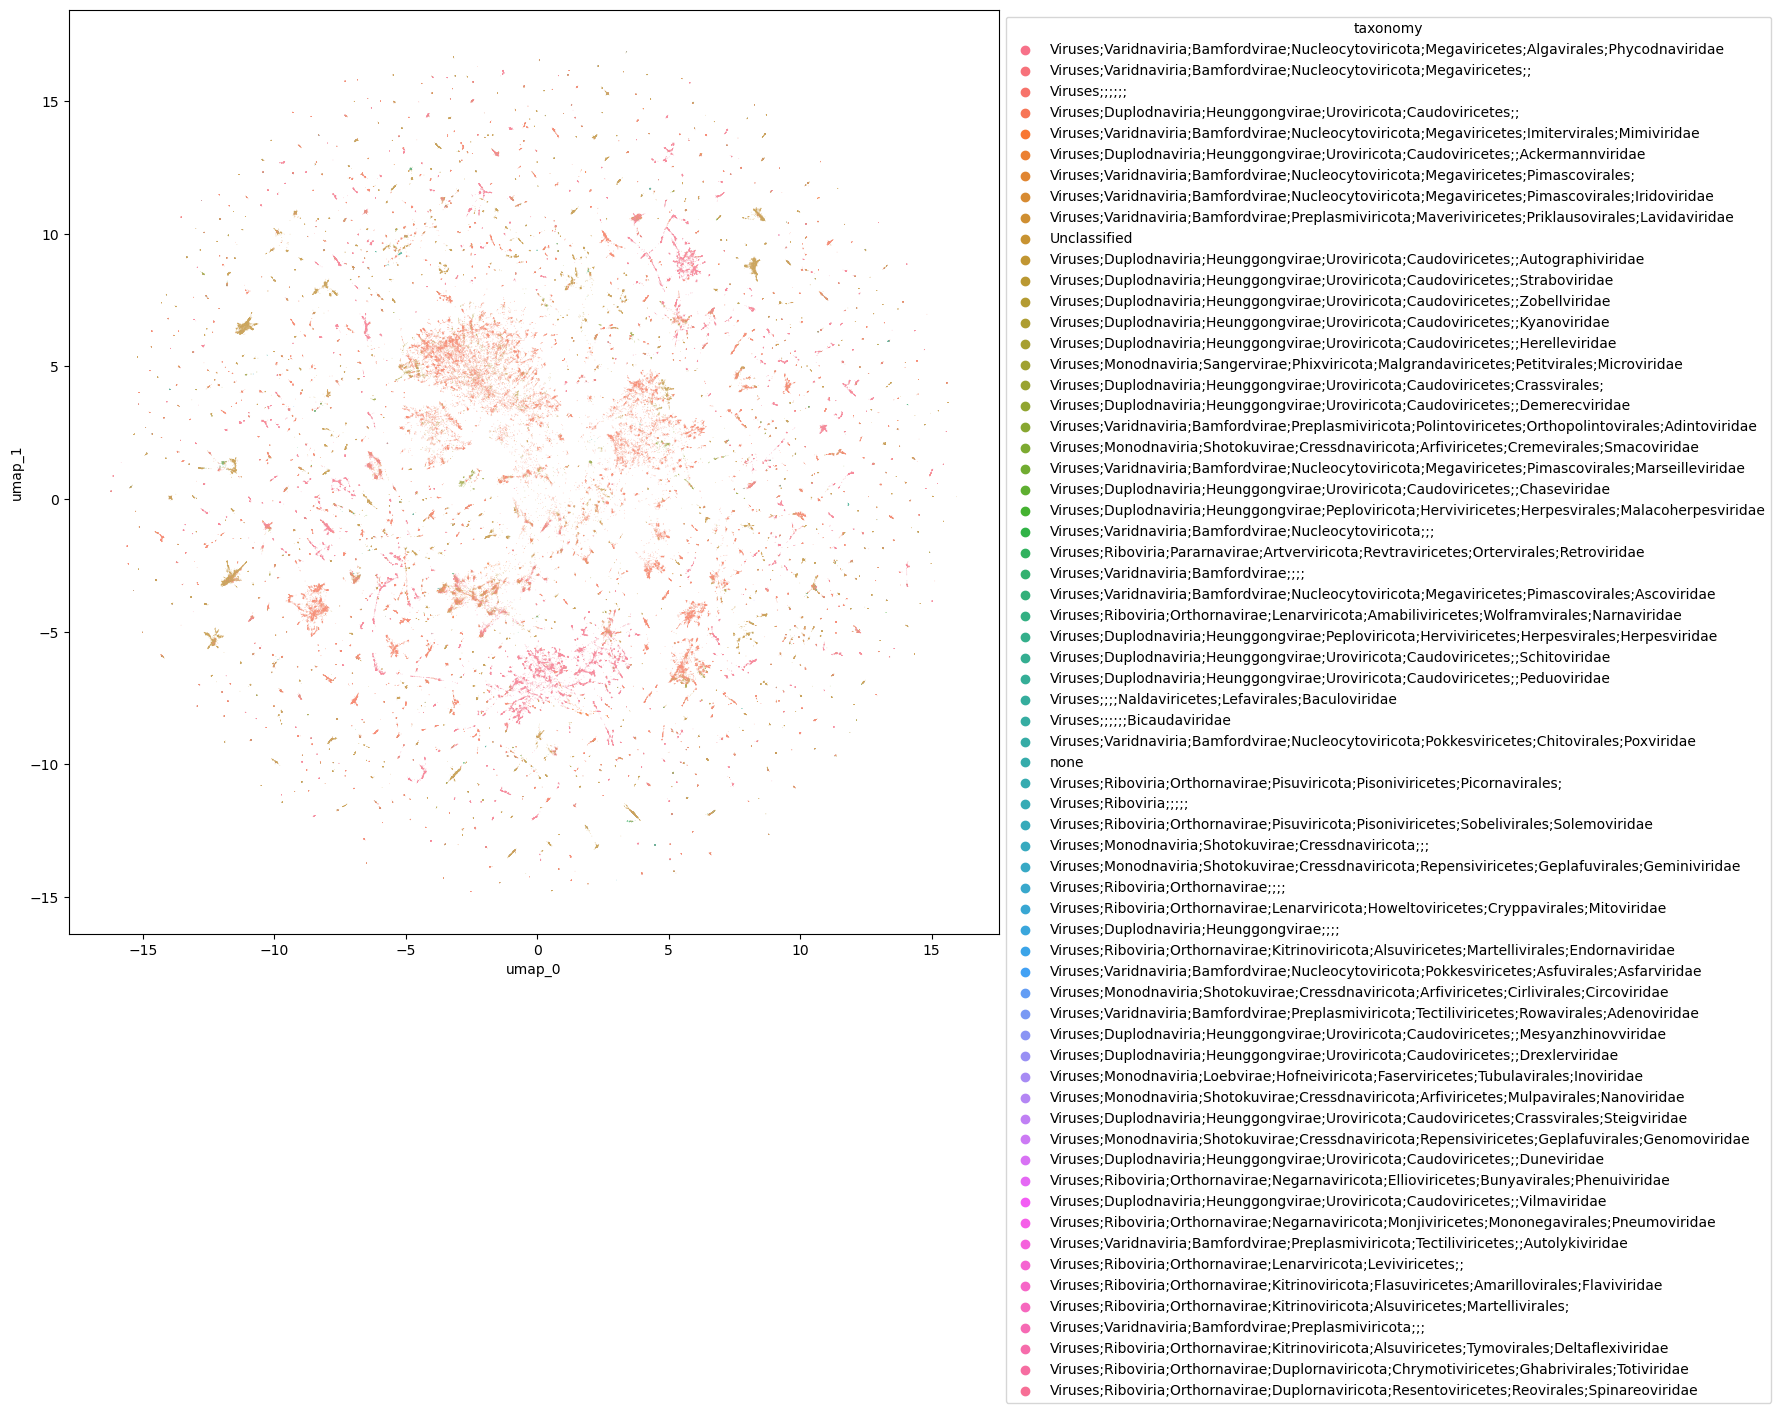

In [154]:
plt.figure(figsize = (12, 12))
ax = sns.scatterplot(
    data = df[df.mbat_bin_id.isin(
        set(df_mt.tail(-1).head(2500).mbat_bin_id)
    ) | df.vamb_bin_id.isin(
        set(df_vt.head(2500).vamb_bin_id)
    )], 
    x = 'umap_0', 
    y = 'umap_1', 
    s = 0.25, 
    hue = 'taxonomy', 
    alpha = 0.5
)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

In [202]:
df = pd.merge(
    df, 
    df_dedup[['bin_all', 'bin_name']], 
    how = 'left', 
    on = 'bin_all', 
    suffixes = ["_orig", "_dedup"]
)

In [203]:
def choose_bin_name(row):
    
    if pd.isna(row.bin_name_dedup):
        return row.bin_name_orig
    
    return row.bin_name_dedup

df['vir_bin_id'] = df.apply(choose_bin_name, axis = 1)

In [206]:
df[['vir_bin_id', 'contig_id']].sort_values('vir_bin_id').to_csv(
    "/gpfs/data/mock_lab/will/mosaic_tmp/mag_catalogue/mag_catalogue_to_bin_vir_v2.tsv", 
    index = False, 
    sep = '\t'
)